# Omni-Grid Supply Chain & Spare Parts Optimization Prototype

## Module: OmniParts-AI

This notebook builds the prototype for the **Supply Chain & Spare Parts Optimization** module using the local dataset:

`synthetic_optimisation_dataset.csv`

The uploaded dataset is mainly an inverter health, predictive maintenance, failure-risk, and RUL dataset. It does not directly contain ERP spare-parts fields such as supplier purchase orders, warehouse inventory, part IDs, or lead times.

Therefore, this notebook uses the dataset as the **predictive maintenance input layer** and builds a spare-parts optimization layer on top of it.

The notebook covers:

1. Loading the local dataset
2. Reviewing the data dictionary
3. Creating component-level spare-part risk signals
4. Mapping inverter health signals to spare parts
5. Creating monthly spare-parts demand records
6. Training a spare-parts demand forecasting model
7. Training a supplier delay risk model
8. Calculating safety stock, reorder points, and recommended order quantities
9. Applying budget-aware procurement allocation
10. Comparing baseline vs optimized inventory decisions
11. Exporting final procurement recommendations


## 1. Import Required Libraries

This section imports the core Python libraries required for data handling, modelling, evaluation, and visualization.


In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

def make_one_hot_encoder():
    """Create a OneHotEncoder that works across different scikit-learn versions."""
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Project Folder Setup

The notebook uses paths relative to its own folder, so it runs on any machine after cloning the repo. Data is read from `./data`. If the full synthetic dataset is not present, the sample file is used instead.

In production, this would be replaced by a shared data source such as an ERP, inventory database or cloud storage pipeline.


In [ ]:
from pathlib import Path

# Portable project folder setup
# This assumes the notebook is inside the main project folder.

PROJECT_DIR = Path.cwd()

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURES_DIR = PROJECT_DIR / "figures"

DATASET_FILE = "synthetic_optimisation_dataset.csv"
SAMPLE_FILE = "synthetic_optimisation_sample.csv"
DICTIONARY_FILE = "synthetic_optimisation_data_dictionary.csv"

DATASET_PATH = DATA_DIR / DATASET_FILE
SAMPLE_PATH = DATA_DIR / SAMPLE_FILE
DICTIONARY_PATH = DATA_DIR / DICTIONARY_FILE

if not DATASET_PATH.exists():
    print(f"Full dataset not found, using sample file: {SAMPLE_PATH.name}")
    DATASET_PATH = SAMPLE_PATH

OUTPUT_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Dataset path:", DATASET_PATH)
print("Output directory:", OUTPUT_DIR)
print("Figures directory:", FIGURES_DIR)

## 3. Load Dataset

This section loads:

- The full synthetic optimization dataset
- The data dictionary
- The sample dataset

The `date` column is parsed as a datetime column.


In [3]:
df = pd.read_csv(DATASET_PATH, parse_dates=["date"])
data_dictionary = pd.read_csv(DICTIONARY_PATH)
sample_df = pd.read_csv(SAMPLE_PATH)

print("Full dataset shape:", df.shape)
print("Sample dataset shape:", sample_df.shape)
print("Data dictionary shape:", data_dictionary.shape)

display(df.head())
display(data_dictionary.head(15))

Full dataset shape: (32627, 42)
Sample dataset shape: (500, 42)
Data dictionary shape: (42, 2)


,date,inverter_id,manufacturer,climate_zone,rated_capacity_kw,installation_quality_score,maintenance_quality_score,age_months,ambient_temperature_c,humidity_pct,...,failed_today,is_censored,efficiency_7d_mean,efficiency_30d_mean,temperature_7d_mean,temperature_30d_mean,efficiency_decline_7d,temp_stress_index,restart_7d_sum,errors_7d_sum
0,2025-01-01,INV-0001,Fronius,Temperate,100,0.789,0.88,83.00,19.57,40.05,...,0,0,97.9300,97.9300,28.510000,28.510000,0.0000,0.0,0.0,0.0
1,2025-01-02,INV-0001,Fronius,Temperate,100,0.789,0.88,83.03,23.48,41.48,...,0,0,97.6950,97.6950,32.575000,32.575000,-0.2350,0.0,0.0,0.0
2,2025-01-03,INV-0001,Fronius,Temperate,100,0.789,0.88,83.07,21.69,45.80,...,0,0,97.8100,97.8100,32.456667,32.456667,0.2300,0.0,0.0,0.0
3,2025-01-04,INV-0001,Fronius,Temperate,100,0.789,0.88,83.10,21.43,22.49,...,0,0,97.7275,97.7275,33.117500,33.117500,-0.2475,0.0,0.0,0.0
4,2025-01-05,INV-0001,Fronius,Temperate,100,0.789,0.88,83.13,23.25,33.41,...,0,0,97.8680,97.8680,33.792000,33.792000,0.5620,0.0,0.0,0.0


,column_name,description
0,date,Observation date
1,inverter_id,Unique inverter identifier
2,manufacturer,Inverter manufacturer
3,climate_zone,Synthetic site climate classification
4,rated_capacity_kw,Rated inverter capacity in kW
5,installation_quality_score,Synthetic installation quality score
6,maintenance_quality_score,Synthetic maintenance quality score
7,age_months,Age of inverter in months
8,ambient_temperature_c,Ambient temperature in Celsius
9,humidity_pct,Humidity percentage


## 4. Initial Data Review

This section checks:

- Column names
- Data types
- Missing values
- Date range
- Number of inverters
- Failure label distribution

This helps confirm whether the dataset is suitable for a spare-parts optimization prototype.


In [4]:
print("Columns in dataset:")
print(df.columns.tolist())

print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).head(20))

print("\nData types:")
display(df.dtypes)

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nNumber of unique inverters:")
print(df["inverter_id"].nunique())

print("\nManufacturers:")
print(df["manufacturer"].unique())

print("\nClimate zones:")
print(df["climate_zone"].unique())

print("\nFailure label distribution:")
display(df[["failure_within_7d", "failure_within_30d", "failure_within_90d", "failed_today"]].mean().to_frame("rate"))

Columns in dataset:
['date', 'inverter_id', 'manufacturer', 'climate_zone', 'rated_capacity_kw', 'installation_quality_score', 'maintenance_quality_score', 'age_months', 'ambient_temperature_c', 'humidity_pct', 'dust_soiling_index', 'uv_exposure_index', 'cumulative_uv_exposure', 'operating_hours_today', 'cumulative_operating_hours', 'cumulative_energy_throughput_mwh', 'efficiency_pct', 'reactive_power_capability', 'internal_temperature_c', 'voltage_ripple', 'current_harmonic_distortion_pct', 'insulation_resistance_mohm', 'capacitor_degradation_indicator', 'fan_speed_rpm', 'restart_count_today', 'error_code_count_today', 'thermal_cycling_count_today', 'overload_events_today', 'failure_within_7d', 'failure_within_30d', 'failure_within_90d', 'rul_days', 'failed_today', 'is_censored', 'efficiency_7d_mean', 'efficiency_30d_mean', 'temperature_7d_mean', 'temperature_30d_mean', 'efficiency_decline_7d', 'temp_stress_index', 'restart_7d_sum', 'errors_7d_sum']

Missing values:


rul_days                       17155
date                               0
fan_speed_rpm                      0
restart_count_today                0
error_code_count_today             0
thermal_cycling_count_today        0
overload_events_today              0
failure_within_7d                  0
failure_within_30d                 0
failure_within_90d                 0
failed_today                       0
inverter_id                        0
is_censored                        0
efficiency_7d_mean                 0
efficiency_30d_mean                0
temperature_7d_mean                0
temperature_30d_mean               0
efficiency_decline_7d              0
temp_stress_index                  0
restart_7d_sum                     0
dtype: int64


Data types:


date                                datetime64[ns]
inverter_id                                 object
manufacturer                                object
climate_zone                                object
rated_capacity_kw                            int64
installation_quality_score                 float64
maintenance_quality_score                  float64
age_months                                 float64
ambient_temperature_c                      float64
humidity_pct                               float64
dust_soiling_index                         float64
uv_exposure_index                          float64
cumulative_uv_exposure                     float64
operating_hours_today                      float64
cumulative_operating_hours                 float64
cumulative_energy_throughput_mwh           float64
efficiency_pct                             float64
reactive_power_capability                  float64
internal_temperature_c                     float64
voltage_ripple                 


Date range:
2025-01-01 00:00:00 to 2025-12-31 00:00:00

Number of unique inverters:
120

Manufacturers:
['Fronius' 'SolarEdge' 'Huawei' 'SMA']

Climate zones:
['Temperate' 'Coastal' 'Hot-Dry' 'Humid-Subtropical']

Failure label distribution:


,rate
failure_within_7d,0.017869
failure_within_30d,0.069329
failure_within_90d,0.198854
failed_today,0.002207


## 5. Dataset Note

This dataset does not directly contain fields such as:

- `part_id`
- `supplier_id`
- `warehouse_stock`
- `purchase_order_history`
- `supplier_lead_time`
- `stockout_events`

Instead, it contains inverter-level health, degradation, failure-risk, and RUL fields.

For this prototype, the dataset is used as the **failure-risk input layer**. Then, component-level spare-parts demand is derived using risk signals such as:

- `failure_within_30d`
- `failure_within_90d`
- `rul_days`
- `capacitor_degradation_indicator`
- `fan_speed_rpm`
- `voltage_ripple`
- `current_harmonic_distortion_pct`
- `insulation_resistance_mohm`
- `restart_count_today`
- `error_code_count_today`
- `efficiency_pct`
- `internal_temperature_c`

This mirrors the real Omni-Grid workflow where predictive maintenance and RUL outputs feed the supply chain optimization module.


## 6. Basic Cleaning and Feature Preparation

This section:

1. Sorts the dataset by inverter and date
2. Fills missing categorical values
3. Fills missing numeric values with medians
4. Creates time features
5. Creates synthetic site and warehouse IDs from inverter IDs

The site and warehouse IDs are required because spare-parts planning usually happens at a site or warehouse level.


In [5]:
df = df.sort_values(["inverter_id", "date"]).reset_index(drop=True)

categorical_cols = ["manufacturer", "climate_zone"]
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

for col in categorical_cols:
    df[col] = df[col].fillna("Unknown")

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

df["month"] = df["date"].dt.month
df["quarter"] = df["date"].dt.quarter
df["year"] = df["date"].dt.year

# Create synthetic site IDs from inverter IDs
inverter_num = (
    df["inverter_id"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .fillna("0")
    .astype(int)
)

df["site_id"] = "SITE-" + (((inverter_num - 1) % 5) + 1).astype(str).str.zfill(3)

df["warehouse_id"] = df["site_id"].map({
    "SITE-001": "WH-NSW",
    "SITE-002": "WH-QLD",
    "SITE-003": "WH-VIC",
    "SITE-004": "WH-SA",
    "SITE-005": "WH-WA"
}).fillna("WH-NSW")

print("Prepared dataset shape:", df.shape)
display(df[["date", "inverter_id", "site_id", "warehouse_id", "manufacturer", "climate_zone"]].head())

Prepared dataset shape: (32627, 47)


,date,inverter_id,site_id,warehouse_id,manufacturer,climate_zone
0,2025-01-01,INV-0001,SITE-001,WH-NSW,Fronius,Temperate
1,2025-01-02,INV-0001,SITE-001,WH-NSW,Fronius,Temperate
2,2025-01-03,INV-0001,SITE-001,WH-NSW,Fronius,Temperate
3,2025-01-04,INV-0001,SITE-001,WH-NSW,Fronius,Temperate
4,2025-01-05,INV-0001,SITE-001,WH-NSW,Fronius,Temperate


## 7. Create Component-Level Spare-Part Risk Scores

This section translates inverter health signals into spare-part risk scores.

The goal is to estimate which type of part is likely to be needed based on the technical condition of the inverter.

The prototype creates risk scores for:

1. Capacitor replacement kit
2. Cooling fan assembly
3. Insulation and sealing kit
4. Power electronics module
5. Communication board
6. Preventive service kit


In [6]:
def scale_between(series, low, high, reverse=False):
    """
    Scale a numeric series to the range 0 to 1.

    If reverse=True, lower values become higher risk.
    """
    scaled = (series - low) / (high - low)
    scaled = scaled.clip(0, 1)

    if reverse:
        scaled = 1 - scaled

    return scaled


df["failure_risk_score"] = (
    0.15 * df["failure_within_7d"]
    + 0.55 * df["failure_within_30d"]
    + 0.30 * df["failure_within_90d"]
).clip(0, 1)

df["rul_urgency_score"] = ((90 - df["rul_days"]) / 90).clip(0, 1)

df["efficiency_decline_risk"] = scale_between(
    -df["efficiency_decline_7d"],
    0,
    1.5
)

df["capacitor_spare_risk"] = (
    0.35 * scale_between(df["capacitor_degradation_indicator"], 0.35, 0.85)
    + 0.20 * scale_between(df["voltage_ripple"], 2.5, 4.5)
    + 0.20 * df["failure_risk_score"]
    + 0.15 * df["rul_urgency_score"]
    + 0.10 * df["efficiency_decline_risk"]
).clip(0, 1)

df["cooling_fan_spare_risk"] = (
    0.25 * scale_between(df["internal_temperature_c"], 38, 55)
    + 0.25 * scale_between(df["temp_stress_index"], 1.5, 8)
    + 0.20 * scale_between(df["fan_speed_rpm"], 1800, 3200, reverse=True)
    + 0.15 * scale_between(df["overload_events_today"], 1, 5)
    + 0.15 * df["failure_risk_score"]
).clip(0, 1)

df["insulation_spare_risk"] = (
    0.30 * scale_between(df["insulation_resistance_mohm"], 60, 85, reverse=True)
    + 0.20 * scale_between(df["humidity_pct"], 60, 95)
    + 0.20 * scale_between(df["dust_soiling_index"], 0.35, 0.85)
    + 0.15 * df["failure_risk_score"]
    + 0.15 * df["rul_urgency_score"]
).clip(0, 1)

df["power_module_spare_risk"] = (
    0.25 * scale_between(df["voltage_ripple"], 2.5, 5.0)
    + 0.20 * scale_between(df["current_harmonic_distortion_pct"], 5, 9)
    + 0.20 * scale_between(df["overload_events_today"], 1, 5)
    + 0.20 * df["failure_risk_score"]
    + 0.15 * df["rul_urgency_score"]
).clip(0, 1)

df["communication_board_spare_risk"] = (
    0.30 * scale_between(df["errors_7d_sum"], 3, 18)
    + 0.25 * scale_between(df["restart_7d_sum"], 2, 14)
    + 0.15 * scale_between(df["error_code_count_today"], 1, 5)
    + 0.15 * scale_between(df["restart_count_today"], 1, 5)
    + 0.15 * df["failure_risk_score"]
).clip(0, 1)

df["service_kit_spare_risk"] = (
    0.25 * scale_between(df["age_months"], 48, 120)
    + 0.20 * scale_between(df["maintenance_quality_score"], 0.70, 0.90, reverse=True)
    + 0.20 * scale_between(df["dust_soiling_index"], 0.35, 0.80)
    + 0.20 * df["efficiency_decline_risk"]
    + 0.15 * scale_between(df["thermal_cycling_count_today"], 1, 6)
).clip(0, 1)

risk_columns = [
    "capacitor_spare_risk",
    "cooling_fan_spare_risk",
    "insulation_spare_risk",
    "power_module_spare_risk",
    "communication_board_spare_risk",
    "service_kit_spare_risk"
]

display(df[risk_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
capacitor_spare_risk,32627.0,0.163672,0.205107,0.0,0.029064,0.091757,0.200519,0.987524
cooling_fan_spare_risk,32627.0,0.143978,0.150277,0.0,0.054771,0.095243,0.164317,1.000000
insulation_spare_risk,32627.0,0.168756,0.128209,0.0,0.073460,0.147280,0.236300,0.802768
power_module_spare_risk,32627.0,0.114041,0.168683,0.0,0.000000,0.050000,0.155975,0.995000
communication_board_spare_risk,32627.0,0.074027,0.176320,0.0,0.000000,0.000000,0.020833,1.000000
service_kit_spare_risk,32627.0,0.256386,0.133214,0.0,0.158486,0.250000,0.348072,0.824882


## 8. Define Spare-Part Catalogue

Because the dataset does not include ERP spare-part records, this prototype creates a small part catalogue.

In a production system, this catalogue would come from ERP, procurement, warehouse, or CMMS systems.


In [7]:
part_catalog = pd.DataFrame([
    {
        "part_id": "CAP-001",
        "part_name": "Inverter capacitor replacement kit",
        "part_category": "Capacitor",
        "supplier_id": "SUP-01",
        "unit_cost": 650,
        "lead_time_days": 21,
        "lead_time_std_days": 5,
        "supplier_delay_rate": 0.18,
        "supplier_quality_score": 88,
        "supplier_on_time_rate": 0.82,
        "min_order_qty": 5,
        "holding_cost_per_unit": 16,
        "stockout_cost_per_unit": 850,
        "part_criticality": 0.95,
        "risk_column": "capacitor_spare_risk"
    },
    {
        "part_id": "FAN-001",
        "part_name": "Cooling fan assembly",
        "part_category": "Cooling",
        "supplier_id": "SUP-02",
        "unit_cost": 320,
        "lead_time_days": 14,
        "lead_time_std_days": 4,
        "supplier_delay_rate": 0.12,
        "supplier_quality_score": 91,
        "supplier_on_time_rate": 0.88,
        "min_order_qty": 10,
        "holding_cost_per_unit": 9,
        "stockout_cost_per_unit": 520,
        "part_criticality": 0.85,
        "risk_column": "cooling_fan_spare_risk"
    },
    {
        "part_id": "INS-001",
        "part_name": "Insulation and sealing kit",
        "part_category": "Insulation",
        "supplier_id": "SUP-03",
        "unit_cost": 180,
        "lead_time_days": 10,
        "lead_time_std_days": 3,
        "supplier_delay_rate": 0.10,
        "supplier_quality_score": 90,
        "supplier_on_time_rate": 0.90,
        "min_order_qty": 20,
        "holding_cost_per_unit": 5,
        "stockout_cost_per_unit": 300,
        "part_criticality": 0.75,
        "risk_column": "insulation_spare_risk"
    },
    {
        "part_id": "PWR-001",
        "part_name": "Power electronics module",
        "part_category": "Power Electronics",
        "supplier_id": "SUP-04",
        "unit_cost": 1250,
        "lead_time_days": 30,
        "lead_time_std_days": 7,
        "supplier_delay_rate": 0.22,
        "supplier_quality_score": 84,
        "supplier_on_time_rate": 0.76,
        "min_order_qty": 3,
        "holding_cost_per_unit": 35,
        "stockout_cost_per_unit": 1600,
        "part_criticality": 1.00,
        "risk_column": "power_module_spare_risk"
    },
    {
        "part_id": "COM-001",
        "part_name": "Communication board",
        "part_category": "Communication",
        "supplier_id": "SUP-05",
        "unit_cost": 460,
        "lead_time_days": 18,
        "lead_time_std_days": 6,
        "supplier_delay_rate": 0.20,
        "supplier_quality_score": 86,
        "supplier_on_time_rate": 0.80,
        "min_order_qty": 8,
        "holding_cost_per_unit": 12,
        "stockout_cost_per_unit": 700,
        "part_criticality": 0.80,
        "risk_column": "communication_board_spare_risk"
    },
    {
        "part_id": "SVC-001",
        "part_name": "Preventive service kit",
        "part_category": "Service Kit",
        "supplier_id": "SUP-06",
        "unit_cost": 95,
        "lead_time_days": 7,
        "lead_time_std_days": 2,
        "supplier_delay_rate": 0.08,
        "supplier_quality_score": 93,
        "supplier_on_time_rate": 0.92,
        "min_order_qty": 30,
        "holding_cost_per_unit": 3,
        "stockout_cost_per_unit": 150,
        "part_criticality": 0.60,
        "risk_column": "service_kit_spare_risk"
    }
])

display(part_catalog)

,part_id,part_name,part_category,supplier_id,unit_cost,lead_time_days,lead_time_std_days,supplier_delay_rate,supplier_quality_score,supplier_on_time_rate,min_order_qty,holding_cost_per_unit,stockout_cost_per_unit,part_criticality,risk_column
0,CAP-001,Inverter capacitor replacement kit,Capacitor,SUP-01,650,21,5,0.18,88,0.82,5,16,850,0.95,capacitor_spare_risk
1,FAN-001,Cooling fan assembly,Cooling,SUP-02,320,14,4,0.12,91,0.88,10,9,520,0.85,cooling_fan_spare_risk
2,INS-001,Insulation and sealing kit,Insulation,SUP-03,180,10,3,0.10,90,0.90,20,5,300,0.75,insulation_spare_risk
3,PWR-001,Power electronics module,Power Electronics,SUP-04,1250,30,7,0.22,84,0.76,3,35,1600,1.00,power_module_spare_risk
4,COM-001,Communication board,Communication,SUP-05,460,18,6,0.20,86,0.80,8,12,700,0.80,communication_board_spare_risk
5,SVC-001,Preventive service kit,Service Kit,SUP-06,95,7,2,0.08,93,0.92,30,3,150,0.60,service_kit_spare_risk


## 9. Convert Inverter Health Records into Spare-Part Demand Records

This section converts the inverter-level dataset into a spare-part demand dataset.

Each inverter health record is expanded into possible spare-part demand signals using the part catalogue.

The resulting demand is still synthetic because the original dataset does not contain real warehouse consumption. However, the demand is driven by the actual technical signals in the dataset.


In [8]:
base_columns = [
    "date",
    "inverter_id",
    "site_id",
    "warehouse_id",
    "manufacturer",
    "climate_zone",
    "rated_capacity_kw",
    "age_months",
    "failure_within_7d",
    "failure_within_30d",
    "failure_within_90d",
    "rul_days",
    "failure_risk_score",
    "rul_urgency_score"
]

daily_part_frames = []

for _, part in part_catalog.iterrows():
    temp = df[base_columns].copy()

    for col in part_catalog.columns:
        if col != "risk_column":
            temp[col] = part[col]

    temp["risk_score"] = df[part["risk_column"]].values

    capacity_factor = (
        temp["rated_capacity_kw"] / temp["rated_capacity_kw"].median()
    ).clip(0.5, 2.5)

    # Risk-driven daily expected spare-part demand
    temp["expected_daily_part_demand"] = (
        0.010
        + 0.18 * temp["risk_score"]
        + 0.10 * temp["failure_within_30d"]
        + 0.07 * temp["rul_urgency_score"]
    ) * temp["part_criticality"] * capacity_factor

    temp["expected_daily_part_demand"] = temp["expected_daily_part_demand"].clip(0, 1.25)

    # Simulated actual demand based on risk-driven expected demand
    temp["actual_daily_part_demand"] = rng.poisson(temp["expected_daily_part_demand"])

    daily_part_frames.append(temp)

daily_parts_df = pd.concat(daily_part_frames, ignore_index=True)

print("Daily spare-parts demand dataset shape:", daily_parts_df.shape)
display(daily_parts_df.head())

Daily spare-parts demand dataset shape: (195762, 31)


,date,inverter_id,site_id,warehouse_id,manufacturer,climate_zone,rated_capacity_kw,age_months,failure_within_7d,failure_within_30d,...,supplier_delay_rate,supplier_quality_score,supplier_on_time_rate,min_order_qty,holding_cost_per_unit,stockout_cost_per_unit,part_criticality,risk_score,expected_daily_part_demand,actual_daily_part_demand
0,2025-01-01,INV-0001,SITE-001,WH-NSW,Fronius,Temperate,100,83.00,0,0,...,0.18,88,0.82,5,16,850,0.95,0.067000,0.020957,0
1,2025-01-02,INV-0001,SITE-001,WH-NSW,Fronius,Temperate,100,83.03,0,0,...,0.18,88,0.82,5,16,850,0.95,0.045667,0.017309,0
2,2025-01-03,INV-0001,SITE-001,WH-NSW,Fronius,Temperate,100,83.07,0,0,...,0.18,88,0.82,5,16,850,0.95,0.057200,0.019281,0
3,2025-01-04,INV-0001,SITE-001,WH-NSW,Fronius,Temperate,100,83.10,0,0,...,0.18,88,0.82,5,16,850,0.95,0.122900,0.030516,0
4,2025-01-05,INV-0001,SITE-001,WH-NSW,Fronius,Temperate,100,83.13,0,0,...,0.18,88,0.82,5,16,850,0.95,0.048800,0.017845,0


## 10. Aggregate Daily Records into Monthly Site-Part Demand

Supply chain planning is usually performed at a monthly or weekly level.

This section aggregates the daily part-level signals into a monthly site-part demand dataset.


In [9]:
daily_parts_df["month_start"] = daily_parts_df["date"].dt.to_period("M").dt.to_timestamp()
daily_parts_df["is_high_risk_signal"] = (daily_parts_df["risk_score"] >= 0.65).astype(int)

def mode_or_first(series):
    mode = series.mode()
    if len(mode) > 0:
        return mode.iloc[0]
    return series.iloc[0]

monthly_parts_df = (
    daily_parts_df
    .groupby([
        "month_start",
        "site_id",
        "warehouse_id",
        "part_id",
        "part_name",
        "part_category",
        "supplier_id"
    ], as_index=False)
    .agg(
        manufacturer=("manufacturer", mode_or_first),
        climate_zone=("climate_zone", mode_or_first),
        actual_monthly_demand=("actual_daily_part_demand", "sum"),
        expected_monthly_demand=("expected_daily_part_demand", "sum"),
        avg_risk_score=("risk_score", "mean"),
        max_risk_score=("risk_score", "max"),
        high_risk_signal_count=("is_high_risk_signal", "sum"),
        failure_7d_count=("failure_within_7d", "sum"),
        failure_30d_count=("failure_within_30d", "sum"),
        failure_90d_count=("failure_within_90d", "sum"),
        avg_rul_days=("rul_days", "mean"),
        avg_failure_risk_score=("failure_risk_score", "mean"),
        avg_rated_capacity_kw=("rated_capacity_kw", "mean"),
        avg_age_months=("age_months", "mean"),
        inverter_count=("inverter_id", "nunique"),
        unit_cost=("unit_cost", "first"),
        lead_time_days=("lead_time_days", "first"),
        lead_time_std_days=("lead_time_std_days", "first"),
        supplier_delay_rate=("supplier_delay_rate", "first"),
        supplier_quality_score=("supplier_quality_score", "first"),
        supplier_on_time_rate=("supplier_on_time_rate", "first"),
        min_order_qty=("min_order_qty", "first"),
        holding_cost_per_unit=("holding_cost_per_unit", "first"),
        stockout_cost_per_unit=("stockout_cost_per_unit", "first"),
        part_criticality=("part_criticality", "first")
    )
)

monthly_parts_df = monthly_parts_df.sort_values(["site_id", "part_id", "month_start"]).reset_index(drop=True)

monthly_parts_df["month"] = monthly_parts_df["month_start"].dt.month
monthly_parts_df["quarter"] = monthly_parts_df["month_start"].dt.quarter
monthly_parts_df["year"] = monthly_parts_df["month_start"].dt.year

print("Monthly spare-parts dataset shape:", monthly_parts_df.shape)
display(monthly_parts_df.head())

Monthly spare-parts dataset shape: (360, 35)


,month_start,site_id,warehouse_id,part_id,part_name,part_category,supplier_id,manufacturer,climate_zone,actual_monthly_demand,...,supplier_delay_rate,supplier_quality_score,supplier_on_time_rate,min_order_qty,holding_cost_per_unit,stockout_cost_per_unit,part_criticality,month,quarter,year
0,2025-01-01,SITE-001,WH-NSW,CAP-001,Inverter capacitor replacement kit,Capacitor,SUP-01,Fronius,Temperate,24,...,0.18,88,0.82,5,16,850,0.95,1,1,2025
1,2025-02-01,SITE-001,WH-NSW,CAP-001,Inverter capacitor replacement kit,Capacitor,SUP-01,Fronius,Temperate,25,...,0.18,88,0.82,5,16,850,0.95,2,1,2025
2,2025-03-01,SITE-001,WH-NSW,CAP-001,Inverter capacitor replacement kit,Capacitor,SUP-01,SMA,Temperate,39,...,0.18,88,0.82,5,16,850,0.95,3,1,2025
3,2025-04-01,SITE-001,WH-NSW,CAP-001,Inverter capacitor replacement kit,Capacitor,SUP-01,SMA,Temperate,50,...,0.18,88,0.82,5,16,850,0.95,4,2,2025
4,2025-05-01,SITE-001,WH-NSW,CAP-001,Inverter capacitor replacement kit,Capacitor,SUP-01,Fronius,Temperate,35,...,0.18,88,0.82,5,16,850,0.95,5,2,2025


## 11. Create Lag, Rolling Demand, Inventory, and Supplier Delay Features

This section adds:

- Previous-month demand
- 3-month rolling demand
- Current stock
- Supplier delay probability
- Supplier delay event

In a real production system, `current_stock` and supplier delays would come from ERP, warehouse, or procurement systems.


In [10]:
group_cols = ["site_id", "part_id"]

monthly_parts_df["demand_lag_1"] = (
    monthly_parts_df.groupby(group_cols)["actual_monthly_demand"].shift(1)
)

monthly_parts_df["demand_rolling_3m"] = (
    monthly_parts_df
    .groupby(group_cols)["actual_monthly_demand"]
    .transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
)

monthly_parts_df["demand_lag_1"] = monthly_parts_df["demand_lag_1"].fillna(
    monthly_parts_df["expected_monthly_demand"]
)

monthly_parts_df["demand_rolling_3m"] = monthly_parts_df["demand_rolling_3m"].fillna(
    monthly_parts_df["expected_monthly_demand"]
)

# Simulated current stock based on recent demand and minimum order quantity
stock_multiplier = rng.uniform(0.8, 2.8, size=len(monthly_parts_df))
stock_noise = rng.normal(0, 3, size=len(monthly_parts_df))

monthly_parts_df["current_stock"] = np.maximum(
    0,
    np.round(
        monthly_parts_df["demand_rolling_3m"] * stock_multiplier
        + monthly_parts_df["min_order_qty"] * rng.uniform(0.2, 1.0, size=len(monthly_parts_df))
        + stock_noise
    )
).astype(int)

# Supplier delay probability and event
monthly_parts_df["supplier_delay_probability"] = np.clip(
    0.08
    + 1.30 * monthly_parts_df["supplier_delay_rate"]
    + 0.012 * monthly_parts_df["lead_time_std_days"]
    + 0.30 * monthly_parts_df["max_risk_score"]
    - 0.006 * (monthly_parts_df["supplier_quality_score"] - 80),
    0.01,
    0.95
)

monthly_parts_df["supplier_delay_event"] = (
    monthly_parts_df["supplier_delay_probability"]
    + rng.normal(0, 0.08, size=len(monthly_parts_df))
    > 0.42
).astype(int)

display(monthly_parts_df[[
    "month_start",
    "site_id",
    "part_id",
    "actual_monthly_demand",
    "demand_lag_1",
    "demand_rolling_3m",
    "current_stock",
    "supplier_delay_probability",
    "supplier_delay_event"
]].head(15))

,month_start,site_id,part_id,actual_monthly_demand,demand_lag_1,demand_rolling_3m,current_stock,supplier_delay_probability,supplier_delay_event
0,2025-01-01,SITE-001,CAP-001,24,25.828978,25.828978,54,0.521400,1
1,2025-02-01,SITE-001,CAP-001,25,24.000000,24.000000,65,0.578257,1
2,2025-03-01,SITE-001,CAP-001,39,25.000000,24.500000,45,0.620560,1
3,2025-04-01,SITE-001,CAP-001,50,39.000000,29.333333,41,0.592980,1
4,2025-05-01,SITE-001,CAP-001,35,50.000000,38.000000,87,0.609451,1
5,2025-06-01,SITE-001,CAP-001,25,35.000000,41.333333,78,0.561363,1
6,2025-07-01,SITE-001,CAP-001,31,25.000000,36.666667,81,0.584899,1
7,2025-08-01,SITE-001,CAP-001,38,31.000000,30.333333,71,0.586760,1
8,2025-09-01,SITE-001,CAP-001,59,38.000000,31.333333,89,0.616314,1
9,2025-10-01,SITE-001,CAP-001,35,59.000000,42.666667,101,0.620143,1


## 12. Feature and Target Definition

We will build two models:

### Model 5A: Spare Parts Demand Forecasting
Target: `actual_monthly_demand`

### Model 5C: Supplier Delay Risk Prediction
Target: `supplier_delay_event`

The inventory optimization step will use the outputs from these two models.


In [11]:
categorical_features = [
    "site_id",
    "warehouse_id",
    "manufacturer",
    "climate_zone",
    "part_id",
    "part_category",
    "supplier_id"
]

numeric_features = [
    "avg_risk_score",
    "max_risk_score",
    "high_risk_signal_count",
    "failure_7d_count",
    "failure_30d_count",
    "failure_90d_count",
    "avg_rul_days",
    "avg_failure_risk_score",
    "avg_rated_capacity_kw",
    "avg_age_months",
    "inverter_count",
    "demand_lag_1",
    "demand_rolling_3m",
    "current_stock",
    "unit_cost",
    "lead_time_days",
    "lead_time_std_days",
    "supplier_delay_rate",
    "supplier_quality_score",
    "supplier_on_time_rate",
    "min_order_qty",
    "holding_cost_per_unit",
    "stockout_cost_per_unit",
    "part_criticality",
    "month",
    "quarter"
]

demand_target = "actual_monthly_demand"
supplier_target = "supplier_delay_event"

print("Categorical features:", categorical_features)
print("Numeric features:", numeric_features)
print("Demand target:", demand_target)
print("Supplier risk target:", supplier_target)

Categorical features: ['site_id', 'warehouse_id', 'manufacturer', 'climate_zone', 'part_id', 'part_category', 'supplier_id']
Numeric features: ['avg_risk_score', 'max_risk_score', 'high_risk_signal_count', 'failure_7d_count', 'failure_30d_count', 'failure_90d_count', 'avg_rul_days', 'avg_failure_risk_score', 'avg_rated_capacity_kw', 'avg_age_months', 'inverter_count', 'demand_lag_1', 'demand_rolling_3m', 'current_stock', 'unit_cost', 'lead_time_days', 'lead_time_std_days', 'supplier_delay_rate', 'supplier_quality_score', 'supplier_on_time_rate', 'min_order_qty', 'holding_cost_per_unit', 'stockout_cost_per_unit', 'part_criticality', 'month', 'quarter']
Demand target: actual_monthly_demand
Supplier risk target: supplier_delay_event


## 13. Temporal Train-Test Split

Because this is a time-related forecasting and planning problem, we use a temporal split.

Earlier months are used for training and the final months are used for testing.


In [12]:
cutoff_date = monthly_parts_df["month_start"].max() - pd.DateOffset(months=3)

train_df = monthly_parts_df[monthly_parts_df["month_start"] < cutoff_date].copy()
test_df = monthly_parts_df[monthly_parts_df["month_start"] >= cutoff_date].copy()

X_train = train_df[categorical_features + numeric_features]
y_train = train_df[demand_target]

X_test = test_df[categorical_features + numeric_features]
y_test = test_df[demand_target]

print("Training period:", train_df["month_start"].min(), "to", train_df["month_start"].max())
print("Testing period:", test_df["month_start"].min(), "to", test_df["month_start"].max())
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training period: 2025-01-01 00:00:00 to 2025-08-01 00:00:00
Testing period: 2025-09-01 00:00:00 to 2025-12-01 00:00:00
Training shape: (240, 40)
Testing shape: (120, 40)


## 14. Model 5A: Spare Parts Demand Forecasting

For the prototype, we use a **Random Forest Regressor**.

This model predicts monthly spare-parts demand using:

- Failure and RUL signals
- Component risk scores
- Historical demand lags
- Rolling demand
- Site, manufacturer, and climate information
- Supplier and part metadata

In production, this can later be upgraded into a stronger time-series forecasting model such as Prophet, XGBoost, LSTM, or Temporal Fusion Transformer.


In [13]:
preprocess = ColumnTransformer(
    transformers=[
        ("cat", make_one_hot_encoder(), categorical_features),
        ("num", "passthrough", numeric_features)
    ]
)

demand_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", RandomForestRegressor(
        n_estimators=250,
        max_depth=14,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

demand_model.fit(X_train, y_train)

print("Demand forecasting model trained successfully.")

Demand forecasting model trained successfully.


## 15. Demand Forecasting Evaluation

We compare the model against a simple baseline.

### Baseline
The baseline assumes demand will follow the previous 3-month rolling average.

### Model
The model uses predictive maintenance, RUL, component risk, supplier, and site-level features.


In [14]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE (%)": np.mean(np.abs((y_true - y_pred) / np.maximum(y_true, 1))) * 100,
        "WMAPE (%)": np.sum(np.abs(y_true - y_pred)) / np.maximum(np.sum(y_true), 1) * 100,
        "R2": r2_score(y_true, y_pred)
    }

demand_pred = demand_model.predict(X_test)
baseline_pred = X_test["demand_rolling_3m"].values

metrics_table = pd.DataFrame([
    regression_metrics(y_test, baseline_pred),
    regression_metrics(y_test, demand_pred)
], index=["Baseline: 3-Month Rolling Demand", "Random Forest Demand Model"])

display(metrics_table)

,MAE,RMSE,MAPE (%),WMAPE (%),R2
Baseline: 3-Month Rolling Demand,10.302778,12.661293,98.576963,47.369093,-0.312703
Random Forest Demand Model,8.482481,9.992054,89.842070,38.999914,0.182440


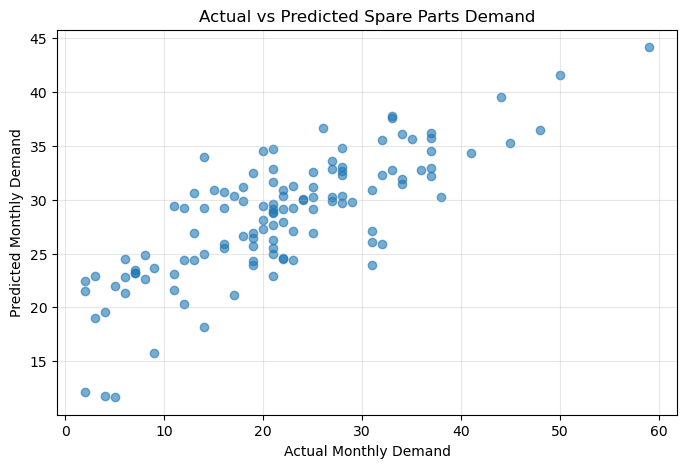

In [15]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, demand_pred, alpha=0.6)
plt.xlabel("Actual Monthly Demand")
plt.ylabel("Predicted Monthly Demand")
plt.title("Actual vs Predicted Spare Parts Demand")
plt.grid(True, alpha=0.3)
plt.show()

## 16. Model 5C: Supplier Delay Risk Prediction

This model predicts whether the next supplier order may be delayed.

The model output is used to adjust safety stock and supply risk.


In [16]:
supplier_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", RandomForestClassifier(
        n_estimators=250,
        max_depth=12,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        class_weight="balanced"
    ))
])

supplier_model.fit(X_train, train_df[supplier_target])

supplier_pred = supplier_model.predict(X_test)
supplier_proba = supplier_model.predict_proba(X_test)[:, 1]

supplier_metrics = {
    "Accuracy": accuracy_score(test_df[supplier_target], supplier_pred),
    "Precision": precision_score(test_df[supplier_target], supplier_pred, zero_division=0),
    "Recall": recall_score(test_df[supplier_target], supplier_pred, zero_division=0),
    "F1 Score": f1_score(test_df[supplier_target], supplier_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(test_df[supplier_target], supplier_proba)
}

display(pd.DataFrame([supplier_metrics], index=["Supplier Delay Risk Model"]))

print("Classification report:")
print(classification_report(test_df[supplier_target], supplier_pred, zero_division=0))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Supplier Delay Risk Model,0.833333,0.896104,0.851852,0.873418,0.911364


Classification report:
              precision    recall  f1-score   support

           0       0.72      0.79      0.76        39
           1       0.90      0.85      0.87        81

    accuracy                           0.83       120
   macro avg       0.81      0.82      0.81       120
weighted avg       0.84      0.83      0.84       120



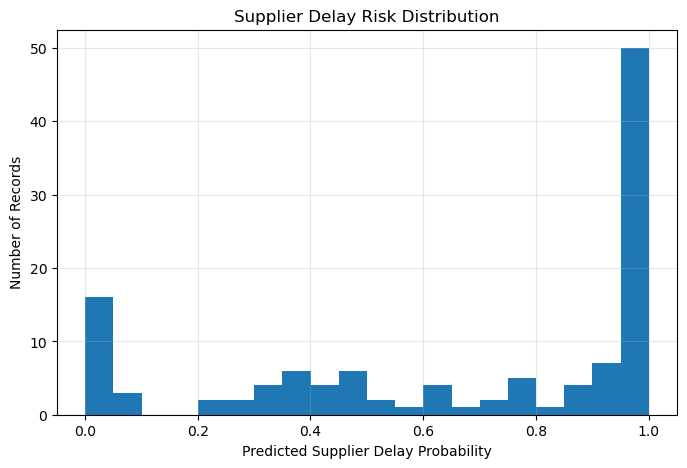

In [17]:
plt.figure(figsize=(8, 5))
plt.hist(supplier_proba, bins=20)
plt.xlabel("Predicted Supplier Delay Probability")
plt.ylabel("Number of Records")
plt.title("Supplier Delay Risk Distribution")
plt.grid(True, alpha=0.3)
plt.show()

## 17. Inventory Optimization Logic

This section converts model outputs into practical supply chain decisions.

The notebook calculates:

1. Forecast monthly demand
2. Supplier delay risk
3. Lead-time demand
4. Safety stock
5. Reorder point
6. Order-up-to level
7. Recommended order quantity
8. Combined supply risk
9. Recommended procurement action


In [18]:
latest_month = monthly_parts_df["month_start"].max()
latest_df = monthly_parts_df[monthly_parts_df["month_start"] == latest_month].copy()

latest_X = latest_df[categorical_features + numeric_features]

latest_df["forecast_monthly_demand"] = np.maximum(
    0,
    np.round(demand_model.predict(latest_X))
).astype(int)

latest_df["supplier_delay_risk"] = supplier_model.predict_proba(latest_X)[:, 1]

recent_df = monthly_parts_df[
    monthly_parts_df["month_start"] < latest_month
].copy()

demand_std = (
    recent_df
    .groupby(["site_id", "part_id"])["actual_monthly_demand"]
    .std()
    .reset_index()
    .rename(columns={"actual_monthly_demand": "demand_std_6m"})
)

latest_df = latest_df.merge(demand_std, on=["site_id", "part_id"], how="left")

latest_df["demand_std_6m"] = latest_df["demand_std_6m"].fillna(
    latest_df["forecast_monthly_demand"].clip(lower=1) * 0.25
)

z_score_service_level = 1.65

latest_df["lead_time_months"] = latest_df["lead_time_days"] / 30.4

latest_df["lead_time_demand"] = (
    latest_df["forecast_monthly_demand"] * latest_df["lead_time_months"]
)

latest_df["safety_stock"] = (
    z_score_service_level
    * latest_df["demand_std_6m"]
    * np.sqrt(latest_df["lead_time_months"].clip(lower=0.1))
    * (1 + 0.50 * latest_df["supplier_delay_risk"])
)

latest_df["reorder_point"] = np.ceil(
    latest_df["lead_time_demand"] + latest_df["safety_stock"]
).astype(int)

latest_df["order_up_to_level"] = np.ceil(
    latest_df["forecast_monthly_demand"] * 1.8 + latest_df["safety_stock"]
).astype(int)

raw_order_qty = latest_df["order_up_to_level"] - latest_df["current_stock"]

latest_df["recommended_order_qty_raw"] = np.where(
    latest_df["current_stock"] < latest_df["reorder_point"],
    np.maximum(raw_order_qty, latest_df["min_order_qty"]),
    0
)

latest_df["recommended_order_qty_raw"] = np.maximum(
    0,
    latest_df["recommended_order_qty_raw"]
).astype(int)

latest_df["expected_order_cost_raw"] = (
    latest_df["recommended_order_qty_raw"] * latest_df["unit_cost"]
)

latest_df["stockout_risk"] = np.clip(
    (
        (latest_df["reorder_point"] - latest_df["current_stock"])
        / latest_df["reorder_point"].replace(0, np.nan)
    ).fillna(0),
    0,
    1
)

latest_df["combined_supply_risk"] = np.clip(
    0.55 * latest_df["stockout_risk"]
    + 0.25 * latest_df["supplier_delay_risk"]
    + 0.20 * latest_df["part_criticality"],
    0,
    1
)

def assign_supply_action(score):
    if score >= 0.75:
        return "Critical - order immediately"
    if score >= 0.55:
        return "High - order this week"
    if score >= 0.35:
        return "Medium - monitor closely"
    return "Low - no immediate order"

latest_df["recommended_action"] = latest_df["combined_supply_risk"].apply(assign_supply_action)

display(latest_df[[
    "site_id",
    "warehouse_id",
    "part_id",
    "part_name",
    "current_stock",
    "forecast_monthly_demand",
    "lead_time_days",
    "safety_stock",
    "reorder_point",
    "recommended_order_qty_raw",
    "supplier_delay_risk",
    "combined_supply_risk",
    "recommended_action"
]].sort_values("combined_supply_risk", ascending=False).head(15))

,site_id,warehouse_id,part_id,part_name,current_stock,forecast_monthly_demand,lead_time_days,safety_stock,reorder_point,recommended_order_qty_raw,supplier_delay_risk,combined_supply_risk,recommended_action
16,SITE-003,WH-VIC,PWR-001,Power electronics module,27,19,30,27.644882,47,35,0.909430,0.661400,High - order this week
1,SITE-001,WH-NSW,COM-001,Communication board,22,29,18,19.822046,37,51,0.988022,0.629978,High - order this week
22,SITE-004,WH-SA,PWR-001,Power electronics module,46,34,30,29.977652,64,46,0.984953,0.600926,High - order this week
13,SITE-003,WH-VIC,COM-001,Communication board,16,12,18,18.446589,26,25,0.902878,0.597258,High - order this week
0,SITE-001,WH-NSW,CAP-001,Inverter capacitor replacement kit,35,35,21,25.688540,50,54,0.966502,0.596626,High - order this week
19,SITE-004,WH-SA,COM-001,Communication board,28,31,18,17.440331,36,46,0.978877,0.526941,Medium - monitor closely
28,SITE-005,WH-WA,PWR-001,Power electronics module,32,16,30,20.957900,37,18,0.909430,0.501682,Medium - monitor closely
10,SITE-002,WH-QLD,PWR-001,Power electronics module,83,32,30,27.566217,60,0,0.994123,0.448531,Medium - monitor closely
4,SITE-001,WH-NSW,PWR-001,Power electronics module,79,35,30,29.457489,64,0,0.987364,0.446841,Medium - monitor closely
12,SITE-003,WH-VIC,CAP-001,Inverter capacitor replacement kit,42,23,21,29.008189,45,29,0.865987,0.443163,Medium - monitor closely


## 18. Budget-Aware Procurement Allocation

In real procurement, the business may not be able to order every recommended part.

This section applies a simple budget-aware allocation method:

1. Sort spare parts by combined supply risk
2. Prioritize high-criticality and high-risk parts
3. Allocate order quantities until the budget is used
4. Skip orders that cannot meet minimum order quantity within the remaining budget


In [19]:
INVENTORY_BUDGET = 250_000

latest_df = latest_df.sort_values(
    ["combined_supply_risk", "part_criticality", "expected_order_cost_raw"],
    ascending=[False, False, True]
).reset_index(drop=True)

remaining_budget = INVENTORY_BUDGET
allocated_quantities = []

for _, row in latest_df.iterrows():
    qty = int(row["recommended_order_qty_raw"])
    cost = qty * row["unit_cost"]

    if qty == 0:
        allocated_quantities.append(0)
    elif cost <= remaining_budget:
        allocated_quantities.append(qty)
        remaining_budget -= cost
    else:
        affordable_qty = int(remaining_budget // row["unit_cost"])

        if affordable_qty >= row["min_order_qty"]:
            allocated_quantities.append(affordable_qty)
            remaining_budget -= affordable_qty * row["unit_cost"]
        else:
            allocated_quantities.append(0)

latest_df["recommended_order_qty"] = allocated_quantities
latest_df["expected_order_cost"] = (
    latest_df["recommended_order_qty"] * latest_df["unit_cost"]
)

print("Initial inventory budget:", INVENTORY_BUDGET)
print("Remaining budget:", round(remaining_budget, 2))
print("Total recommended order cost:", round(latest_df["expected_order_cost"].sum(), 2))

display(latest_df[[
    "site_id",
    "warehouse_id",
    "part_id",
    "part_name",
    "current_stock",
    "forecast_monthly_demand",
    "reorder_point",
    "recommended_order_qty",
    "unit_cost",
    "expected_order_cost",
    "combined_supply_risk",
    "recommended_action"
]].head(20))

Initial inventory budget: 250000
Remaining budget: 16180
Total recommended order cost: 233820


,site_id,warehouse_id,part_id,part_name,current_stock,forecast_monthly_demand,reorder_point,recommended_order_qty,unit_cost,expected_order_cost,combined_supply_risk,recommended_action
0,SITE-003,WH-VIC,PWR-001,Power electronics module,27,19,47,35,1250,43750,0.661400,High - order this week
1,SITE-001,WH-NSW,COM-001,Communication board,22,29,37,51,460,23460,0.629978,High - order this week
2,SITE-004,WH-SA,PWR-001,Power electronics module,46,34,64,46,1250,57500,0.600926,High - order this week
3,SITE-003,WH-VIC,COM-001,Communication board,16,12,26,25,460,11500,0.597258,High - order this week
4,SITE-001,WH-NSW,CAP-001,Inverter capacitor replacement kit,35,35,50,54,650,35100,0.596626,High - order this week
5,SITE-004,WH-SA,COM-001,Communication board,28,31,36,46,460,21160,0.526941,Medium - monitor closely
6,SITE-005,WH-WA,PWR-001,Power electronics module,32,16,37,18,1250,22500,0.501682,Medium - monitor closely
7,SITE-002,WH-QLD,PWR-001,Power electronics module,83,32,60,0,1250,0,0.448531,Medium - monitor closely
8,SITE-001,WH-NSW,PWR-001,Power electronics module,79,35,64,0,1250,0,0.446841,Medium - monitor closely
9,SITE-003,WH-VIC,CAP-001,Inverter capacitor replacement kit,42,23,45,29,650,18850,0.443163,Medium - monitor closely


## 19. Baseline vs Optimized Inventory Evaluation

We compare:

### Manual Baseline
A simple reactive rule based on rolling historical demand.

### Optimized Recommendation
Uses demand forecasts, lead-time demand, supplier risk, safety stock, and budget allocation.

The comparison uses a risk-adjusted operational cost:

`Risk-Adjusted Operational Cost = Holding Cost + Stockout Cost`


In [20]:
latest_df["manual_baseline_order_qty"] = np.where(
    latest_df["current_stock"] < latest_df["demand_rolling_3m"] * 1.2,
    np.maximum(
        np.ceil(latest_df["demand_rolling_3m"] * 2.0 - latest_df["current_stock"]).astype(int),
        latest_df["min_order_qty"]
    ),
    0
)

latest_df["manual_baseline_order_qty"] = np.maximum(
    0,
    latest_df["manual_baseline_order_qty"]
).astype(int)

def inventory_cost_summary(df_cost, order_col):
    available_after_order = df_cost["current_stock"] + df_cost[order_col]

    expected_shortage = np.maximum(
        df_cost["forecast_monthly_demand"] + df_cost["lead_time_demand"] - available_after_order,
        0
    )

    expected_surplus = np.maximum(
        available_after_order - df_cost["forecast_monthly_demand"],
        0
    )

    purchase_investment = df_cost[order_col] * df_cost["unit_cost"]
    holding_cost = expected_surplus * df_cost["holding_cost_per_unit"]
    stockout_cost = (
        expected_shortage
        * df_cost["stockout_cost_per_unit"]
        * (1 + df_cost["supplier_delay_risk"])
    )

    return pd.Series({
        "purchase_investment": purchase_investment.sum(),
        "holding_cost": holding_cost.sum(),
        "stockout_cost": stockout_cost.sum(),
        "risk_adjusted_operational_cost": (holding_cost + stockout_cost).sum(),
        "expected_shortage_units": expected_shortage.sum(),
        "service_level_proxy": 1 - (
            expected_shortage.sum() / max(df_cost["forecast_monthly_demand"].sum(), 1)
        )
    })

cost_summary = pd.DataFrame({
    "Manual Baseline": inventory_cost_summary(latest_df, "manual_baseline_order_qty"),
    "Optimized Recommendation": inventory_cost_summary(latest_df, "recommended_order_qty")
}).T

display(cost_summary)

risk_cost_reduction = (
    1
    - cost_summary.loc["Optimized Recommendation", "risk_adjusted_operational_cost"]
    / cost_summary.loc["Manual Baseline", "risk_adjusted_operational_cost"]
) * 100

service_level_improvement = (
    cost_summary.loc["Optimized Recommendation", "service_level_proxy"]
    - cost_summary.loc["Manual Baseline", "service_level_proxy"]
) * 100

print(f"Risk-adjusted operational cost reduction: {risk_cost_reduction:.2f}%")
print(f"Service level improvement: {service_level_improvement:.2f} percentage points")

,purchase_investment,holding_cost,stockout_cost,risk_adjusted_operational_cost,expected_shortage_units,service_level_proxy
Manual Baseline,51270.0,10516.0,149032.628210,159548.628210,65.046053,0.918996
Optimized Recommendation,233820.0,15416.0,26336.017394,41752.017394,21.953947,0.972660


Risk-adjusted operational cost reduction: 73.83%
Service level improvement: 5.37 percentage points


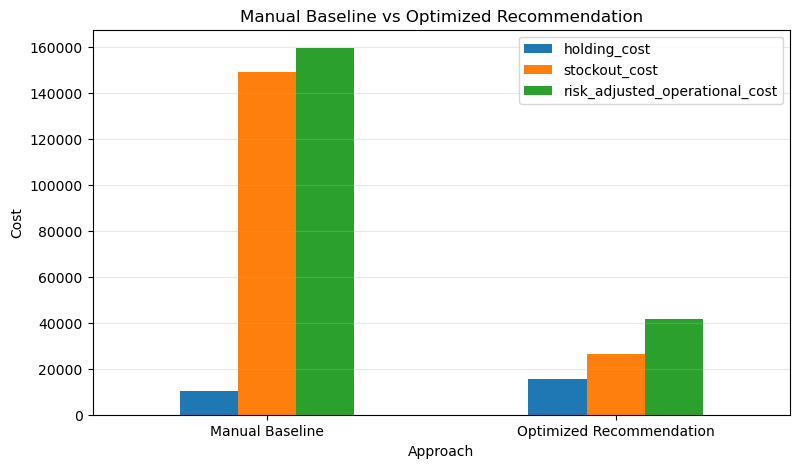

In [21]:
plot_data = cost_summary[[
    "holding_cost",
    "stockout_cost",
    "risk_adjusted_operational_cost"
]]

plot_data.plot(kind="bar", figsize=(9, 5))
plt.title("Manual Baseline vs Optimized Recommendation")
plt.ylabel("Cost")
plt.xlabel("Approach")
plt.xticks(rotation=0)
plt.grid(True, axis="y", alpha=0.3)
plt.show()

## 20. Prototype Visualizations

The following plots are useful for explaining the prototype to stakeholders.


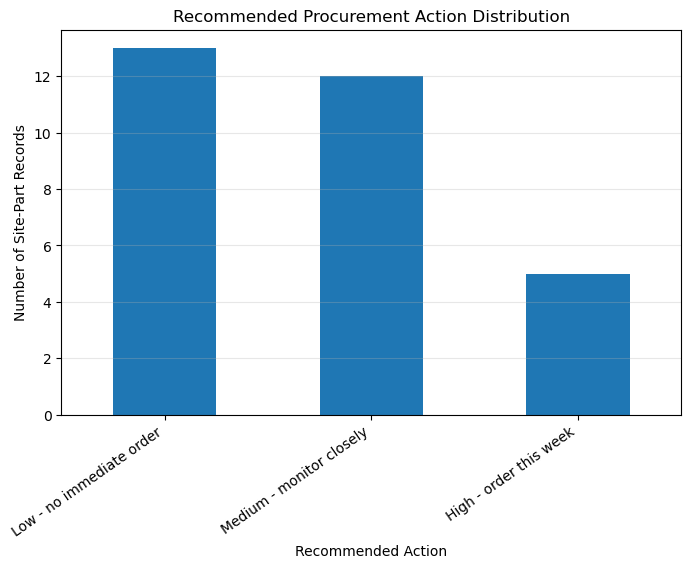

In [22]:
action_counts = latest_df["recommended_action"].value_counts()

plt.figure(figsize=(8, 5))
action_counts.plot(kind="bar")
plt.title("Recommended Procurement Action Distribution")
plt.xlabel("Recommended Action")
plt.ylabel("Number of Site-Part Records")
plt.xticks(rotation=35, ha="right")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

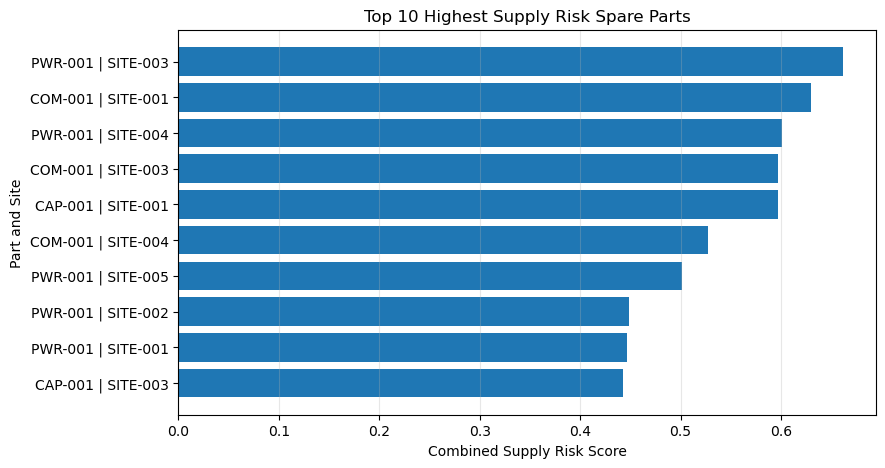

In [23]:
top_risk = latest_df.sort_values("combined_supply_risk", ascending=False).head(10)

plt.figure(figsize=(9, 5))
plt.barh(top_risk["part_id"] + " | " + top_risk["site_id"], top_risk["combined_supply_risk"])
plt.xlabel("Combined Supply Risk Score")
plt.ylabel("Part and Site")
plt.title("Top 10 Highest Supply Risk Spare Parts")
plt.gca().invert_yaxis()
plt.grid(True, axis="x", alpha=0.3)
plt.show()

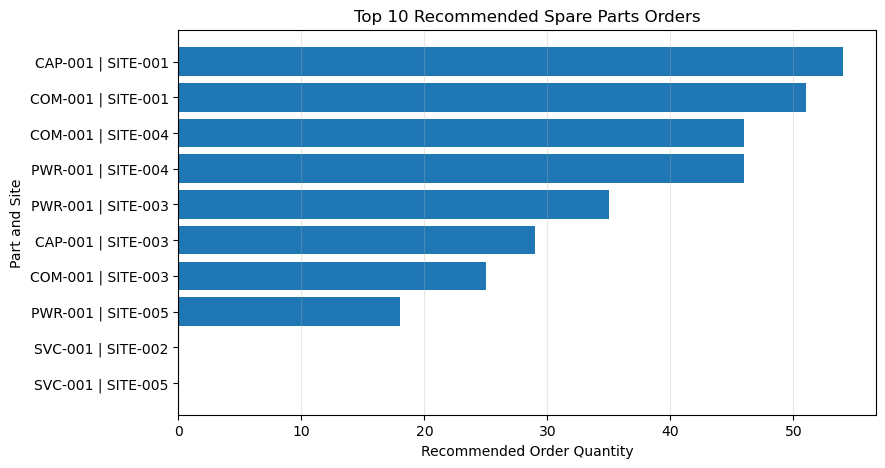

In [24]:
top_orders = latest_df.sort_values("recommended_order_qty", ascending=False).head(10)

plt.figure(figsize=(9, 5))
plt.barh(top_orders["part_id"] + " | " + top_orders["site_id"], top_orders["recommended_order_qty"])
plt.xlabel("Recommended Order Quantity")
plt.ylabel("Part and Site")
plt.title("Top 10 Recommended Spare Parts Orders")
plt.gca().invert_yaxis()
plt.grid(True, axis="x", alpha=0.3)
plt.show()

,supplier_id,avg_supplier_delay_risk,total_expected_order_cost,total_recommended_qty
3,SUP-04,0.957060,123750,99
4,SUP-05,0.954559,56120,122
0,SUP-01,0.926207,53950,83
1,SUP-02,0.559346,0,0
2,SUP-03,0.351052,0,0
5,SUP-06,0.038845,0,0


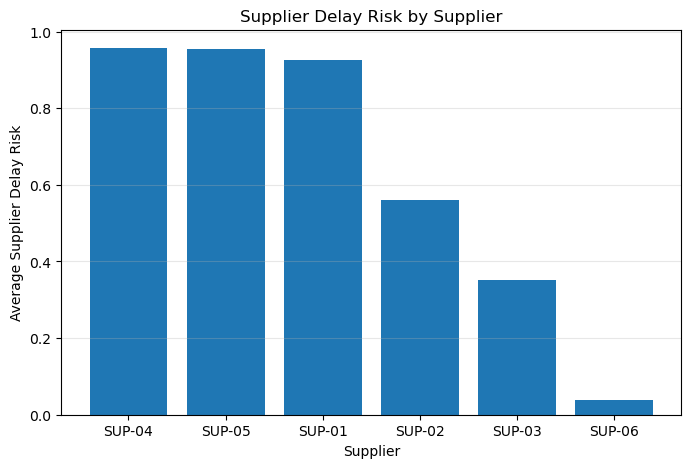

In [25]:
supplier_summary = (
    latest_df
    .groupby("supplier_id", as_index=False)
    .agg(
        avg_supplier_delay_risk=("supplier_delay_risk", "mean"),
        total_expected_order_cost=("expected_order_cost", "sum"),
        total_recommended_qty=("recommended_order_qty", "sum")
    )
    .sort_values("avg_supplier_delay_risk", ascending=False)
)

display(supplier_summary)

plt.figure(figsize=(8, 5))
plt.bar(supplier_summary["supplier_id"], supplier_summary["avg_supplier_delay_risk"])
plt.xlabel("Supplier")
plt.ylabel("Average Supplier Delay Risk")
plt.title("Supplier Delay Risk by Supplier")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

## 21. Final Recommended Procurement Table

This is the main output of the notebook.

The table shows which spare parts should be ordered, in what quantity, and why.


In [26]:
final_recommendations = latest_df[[
    "month_start",
    "site_id",
    "warehouse_id",
    "part_id",
    "part_name",
    "part_category",
    "supplier_id",
    "manufacturer",
    "climate_zone",
    "current_stock",
    "forecast_monthly_demand",
    "demand_std_6m",
    "lead_time_days",
    "safety_stock",
    "reorder_point",
    "order_up_to_level",
    "recommended_order_qty",
    "unit_cost",
    "expected_order_cost",
    "supplier_delay_risk",
    "stockout_risk",
    "part_criticality",
    "combined_supply_risk",
    "recommended_action"
]].sort_values("combined_supply_risk", ascending=False)

display(final_recommendations.head(25))

output_file = OUTPUT_DIR / "spare_parts_procurement_recommendations.csv"
final_recommendations.to_csv(output_file, index=False)

monthly_output_file = OUTPUT_DIR / "monthly_spare_parts_training_dataset.csv"
monthly_parts_df.to_csv(monthly_output_file, index=False)

print("Final recommendations exported to:", output_file)
print("Monthly training dataset exported to:", monthly_output_file)

,month_start,site_id,warehouse_id,part_id,part_name,part_category,supplier_id,manufacturer,climate_zone,current_stock,...,reorder_point,order_up_to_level,recommended_order_qty,unit_cost,expected_order_cost,supplier_delay_risk,stockout_risk,part_criticality,combined_supply_risk,recommended_action
0,2025-12-01,SITE-003,WH-VIC,PWR-001,Power electronics module,Power Electronics,SUP-04,SMA,Coastal,27,...,47,62,35,1250,43750,0.909430,0.425532,1.00,0.661400,High - order this week
1,2025-12-01,SITE-001,WH-NSW,COM-001,Communication board,Communication,SUP-05,Fronius,Temperate,22,...,37,73,51,460,23460,0.988022,0.405405,0.80,0.629978,High - order this week
2,2025-12-01,SITE-004,WH-SA,PWR-001,Power electronics module,Power Electronics,SUP-04,SMA,Coastal,46,...,64,92,46,1250,57500,0.984953,0.281250,1.00,0.600926,High - order this week
3,2025-12-01,SITE-003,WH-VIC,COM-001,Communication board,Communication,SUP-05,SMA,Coastal,16,...,26,41,25,460,11500,0.902878,0.384615,0.80,0.597258,High - order this week
4,2025-12-01,SITE-001,WH-NSW,CAP-001,Inverter capacitor replacement kit,Capacitor,SUP-01,Fronius,Temperate,35,...,50,89,54,650,35100,0.966502,0.300000,0.95,0.596626,High - order this week
5,2025-12-01,SITE-004,WH-SA,COM-001,Communication board,Communication,SUP-05,SMA,Coastal,28,...,36,74,46,460,21160,0.978877,0.222222,0.80,0.526941,Medium - monitor closely
6,2025-12-01,SITE-005,WH-WA,PWR-001,Power electronics module,Power Electronics,SUP-04,Fronius,Coastal,32,...,37,50,18,1250,22500,0.909430,0.135135,1.00,0.501682,Medium - monitor closely
7,2025-12-01,SITE-002,WH-QLD,PWR-001,Power electronics module,Power Electronics,SUP-04,SMA,Coastal,83,...,60,86,0,1250,0,0.994123,0.000000,1.00,0.448531,Medium - monitor closely
8,2025-12-01,SITE-001,WH-NSW,PWR-001,Power electronics module,Power Electronics,SUP-04,Fronius,Temperate,79,...,64,93,0,1250,0,0.987364,0.000000,1.00,0.446841,Medium - monitor closely
9,2025-12-01,SITE-003,WH-VIC,CAP-001,Inverter capacitor replacement kit,Capacitor,SUP-01,SMA,Coastal,42,...,45,71,29,650,18850,0.865987,0.066667,0.95,0.443163,Medium - monitor closely


Final recommendations exported to: .Monthly training dataset exported to: .

## 22. Summary

This notebook demonstrates a working prototype for the **Supply Chain & Spare Parts Optimization** module.

### What was built

1. The inverter health dataset was loaded from the local project directory.
2. Inverter health signals were translated into component-level spare-part risk scores.
3. A spare-part catalogue was created for prototype modelling.
4. Daily risk signals were aggregated into monthly site-part demand records.
5. A demand forecasting model was trained.
6. A supplier delay risk model was trained.
7. Safety stock and reorder points were calculated.
8. Budget-aware order allocation was applied.
9. Final procurement recommendations were exported.

### How this connects to Omni-Grid

This module connects predictive maintenance with supply chain planning. Instead of waiting for a failure and then checking whether a part is available, the system uses failure risk, RUL, degradation, and anomaly signals to prepare spare parts earlier.

### Future improvements

The next version can be improved by adding:

- Real ERP inventory data
- Real supplier purchase order history
- Real warehouse stock levels
- Real maintenance work orders
- Multi-warehouse transfer optimization
- Linear programming or simulated annealing inventory optimization
- Integration with the AI-Driven Maintenance Scheduling Optimizer
